### 1 : Load Analytical Data


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path("..") if Path("../data").exists() else Path(".")
data_dir = project_root / "data"
output_dir = project_root / "outputs"
figures_dir = output_dir / "eda_figures"

figures_dir.mkdir(parents=True, exist_ok=True)

job_data = pd.read_csv(data_dir / "job-descriptions-tagged.csv")
skill_data = pd.read_csv(data_dir / "skill-list.csv")

def parse_tags(tag_string):
    if not isinstance(tag_string, str) or not tag_string.strip():
        return []
    return [token.strip() for token in tag_string.split(";") if token.strip()]

job_data["parsed_tags"] = job_data["model_tags"].apply(parse_tags)
job_data["tag_count"] = job_data["parsed_tags"].apply(len)
canonical_skills = set(skill_data["skill"].str.strip())


### 2 : Dataset Overview


In [2]:
all_prediction_tokens = [
    token for tag_list in job_data["parsed_tags"] for token in tag_list
]
unique_prediction_tokens = sorted(list(set(all_prediction_tokens)))
exact_canonical_tokens = [t for t in unique_prediction_tokens if t in canonical_skills]
oov_prediction_tokens = [t for t in unique_prediction_tokens if t not in canonical_skills]

overview_metrics = [
    {"Metric": "Total Job Descriptions", "Value": len(job_data)},
    {"Metric": "Unique Job IDs", "Value": job_data["jd_id"].nunique()},
    {"Metric": "Unique Companies", "Value": job_data["company"].nunique()},
    {"Metric": "Unique Job Titles", "Value": job_data["title"].nunique()},
    {"Metric": "Canonical Skills in Vocabulary", "Value": len(canonical_skills)},
    {"Metric": "Total Raw Prediction Instances", "Value": len(all_prediction_tokens)},
    {"Metric": "Unique Predicted Tag Strings", "Value": len(unique_prediction_tokens)},
    {"Metric": "Exact Canonical Prediction Strings", "Value": len(exact_canonical_tokens)},
    {"Metric": "Out-of-Vocabulary Prediction Strings", "Value": len(oov_prediction_tokens)},
]

eda_dataset_summary_df = pd.DataFrame(overview_metrics)
eda_dataset_summary_df.to_csv(output_dir / "eda_dataset_summary.csv", index=False)
display(eda_dataset_summary_df)


,Metric,Value
0,Total Job Descriptions,50
1,Unique Job IDs,50
2,Unique Companies,10
3,Unique Job Titles,10
4,Canonical Skills in Vocabulary,54
5,Total Raw Prediction Instances,200
6,Unique Predicted Tag Strings,61
7,Exact Canonical Prediction Strings,48
8,Out-of-Vocabulary Prediction Strings,13


### 3 : Job Description Length Distribution


In [3]:
job_data["char_length"] = job_data["description"].astype(str).str.len()
job_data["word_count"] = job_data["description"].astype(str).apply(lambda s: len(s.split()))

length_stats = [
    {
        "Dimension": "Character Count",
        "Min": int(job_data["char_length"].min()),
        "Max": int(job_data["char_length"].max()),
        "Mean": round(float(job_data["char_length"].mean()), 2),
        "Median": round(float(job_data["char_length"].median()), 2),
        "Std Dev": round(float(job_data["char_length"].std()), 2),
    },
    {
        "Dimension": "Word Count",
        "Min": int(job_data["word_count"].min()),
        "Max": int(job_data["word_count"].max()),
        "Mean": round(float(job_data["word_count"].mean()), 2),
        "Median": round(float(job_data["word_count"].median()), 2),
        "Std Dev": round(float(job_data["word_count"].std()), 2),
    },
]

length_stats_df = pd.DataFrame(length_stats)
display(length_stats_df)


,Dimension,Min,Max,Mean,Median,Std Dev
0,Character Count,253,316,284.96,285.0,14.63
1,Word Count,40,52,48.02,48.0,2.59


### 4 : Visualization - Document Length Distributions


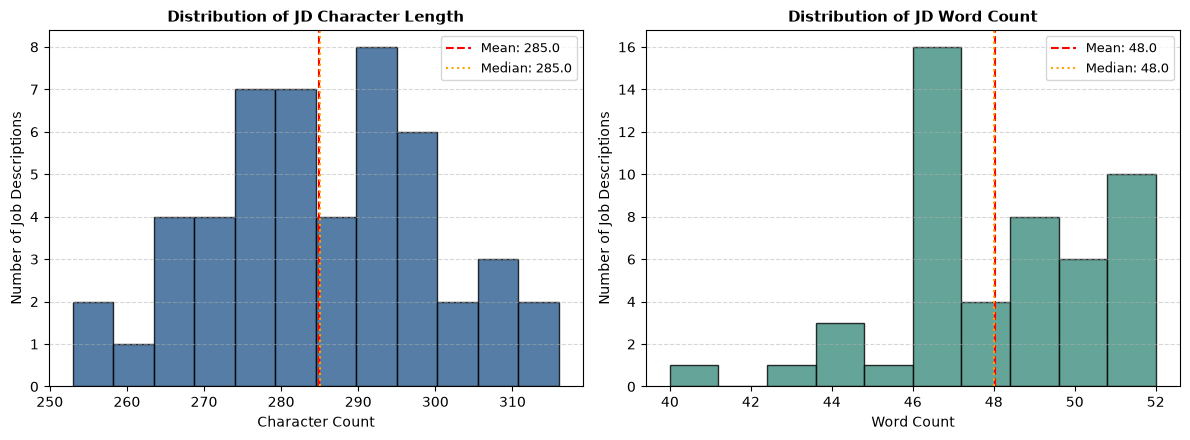

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(job_data["char_length"], bins=12, color="#2b5c8f", edgecolor="black", alpha=0.8)
axes[0].axvline(job_data["char_length"].mean(), color="red", linestyle="--", label=f"Mean: {job_data['char_length'].mean():.1f}")
axes[0].axvline(job_data["char_length"].median(), color="orange", linestyle=":", label=f"Median: {job_data['char_length'].median():.1f}")
axes[0].set_title("Distribution of JD Character Length", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Character Count", fontsize=10)
axes[0].set_ylabel("Number of Job Descriptions", fontsize=10)
axes[0].legend(fontsize=9)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].hist(job_data["word_count"], bins=10, color="#3e8e7e", edgecolor="black", alpha=0.8)
axes[1].axvline(job_data["word_count"].mean(), color="red", linestyle="--", label=f"Mean: {job_data['word_count'].mean():.1f}")
axes[1].axvline(job_data["word_count"].median(), color="orange", linestyle=":", label=f"Median: {job_data['word_count'].median():.1f}")
axes[1].set_title("Distribution of JD Word Count", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Word Count", fontsize=10)
axes[1].set_ylabel("Number of Job Descriptions", fontsize=10)
axes[1].legend(fontsize=9)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(figures_dir / "jd_length_distribution.png", dpi=300)
plt.show()


### 5 : Predicted Tags Per Job Description


In [5]:
tag_stats = [
    {
        "Metric": "Minimum Tags per JD",
        "Value": int(job_data["tag_count"].min()),
    },
    {
        "Metric": "Maximum Tags per JD",
        "Value": int(job_data["tag_count"].max()),
    },
    {
        "Metric": "Mean Tags per JD",
        "Value": round(float(job_data["tag_count"].mean()), 2),
    },
    {
        "Metric": "Median Tags per JD",
        "Value": round(float(job_data["tag_count"].median()), 2),
    },
    {
        "Metric": "Standard Deviation",
        "Value": round(float(job_data["tag_count"].std()), 2),
    },
]

tag_stats_df = pd.DataFrame(tag_stats)
display(tag_stats_df)


,Metric,Value
0,Minimum Tags per JD,1.00
1,Maximum Tags per JD,7.00
2,Mean Tags per JD,4.00
3,Median Tags per JD,4.00
4,Standard Deviation,1.36


### 6 : Tag Density Frequency Breakdown and Visualization


,Tags Emitted,Job Descriptions,Percentage (%)
0,1,1,2.0
1,2,5,10.0
2,3,14,28.0
3,4,12,24.0
4,5,10,20.0
5,6,7,14.0
6,7,1,2.0


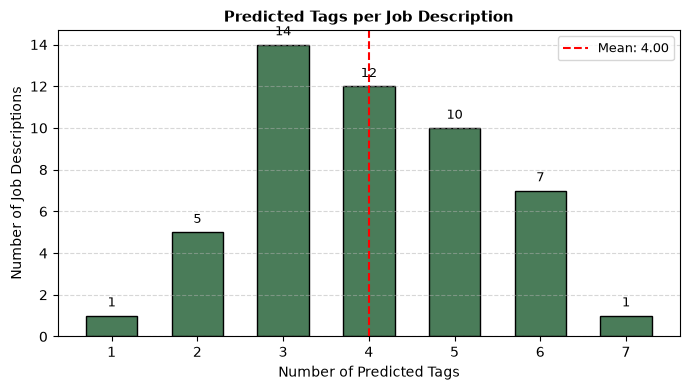

In [6]:
tag_count_freq = job_data["tag_count"].value_counts().sort_index()
tag_freq_df = pd.DataFrame(
    {
        "Tags Emitted": tag_count_freq.index,
        "Job Descriptions": tag_count_freq.values,
        "Percentage (%)": [round((c / len(job_data)) * 100, 2) for c in tag_count_freq.values],
    }
)
display(tag_freq_df)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(tag_count_freq.index, tag_count_freq.values, color="#4a7c59", edgecolor="black", width=0.6)
ax.axvline(job_data["tag_count"].mean(), color="red", linestyle="--", label=f"Mean: {job_data['tag_count'].mean():.2f}")
ax.set_title("Predicted Tags per Job Description", fontsize=11, fontweight="bold")
ax.set_xlabel("Number of Predicted Tags", fontsize=10)
ax.set_ylabel("Number of Job Descriptions", fontsize=10)
ax.set_xticks(tag_count_freq.index)
ax.legend(fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, yval + 0.3, int(yval), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(figures_dir / "predicted_tags_per_jd.png", dpi=300)
plt.show()


### 7 : Outlier Prediction Volumes


In [7]:
outliers_df = job_data[job_data["tag_count"].isin([job_data["tag_count"].min(), job_data["tag_count"].max()])][
    ["jd_id", "title", "company", "tag_count", "model_tags"]
]
display(outliers_df)


,jd_id,title,company,tag_count,model_tags
9,JD010,HR Intern,Tarang Media,1,Recruiting
10,JD011,Data Analyst Intern,Vayu Mobility,7,SQL; Power BI; Data Cleaning; Leadership; Pyth...


### 8 : Most Frequently Predicted Skills


,Skill Tag,Emission Count,Percentage of All Tokens (%),Corpus Prevalence (% of 50 JDs)
0,Python,10,5.0,20.0
1,Microsoft Excel,8,4.0,16.0
2,Leadership,7,3.5,14.0
3,Statistics,6,3.0,12.0
4,SQL,6,3.0,12.0
5,Git,6,3.0,12.0
6,Recruiting,5,2.5,10.0
7,Email Marketing,5,2.5,10.0
8,Excel,5,2.5,10.0
9,PyTorch,5,2.5,10.0


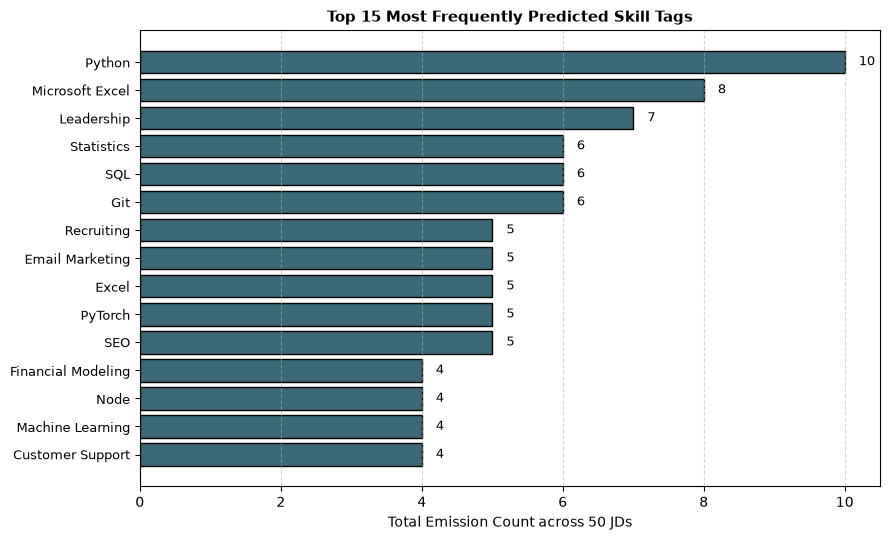

In [8]:
tag_frequency_series = pd.Series(all_prediction_tokens).value_counts()

top_15_tags_df = pd.DataFrame(
    {
        "Skill Tag": tag_frequency_series.head(15).index,
        "Emission Count": tag_frequency_series.head(15).values,
        "Percentage of All Tokens (%)": [
            round((c / len(all_prediction_tokens)) * 100, 2) for c in tag_frequency_series.head(15).values
        ],
        "Corpus Prevalence (% of 50 JDs)": [
            round((c / len(job_data)) * 100, 2) for c in tag_frequency_series.head(15).values
        ],
    }
)
display(top_15_tags_df)

fig, ax = plt.subplots(figsize=(9, 5.5))
y_pos = np.arange(len(top_15_tags_df))
ax.barh(y_pos, top_15_tags_df["Emission Count"], color="#3b6978", edgecolor="black")
ax.set_yticks(y_pos)
ax.set_yticklabels(top_15_tags_df["Skill Tag"], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Total Emission Count across 50 JDs", fontsize=10)
ax.set_title("Top 15 Most Frequently Predicted Skill Tags", fontsize=11, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.5)

for i, count in enumerate(top_15_tags_df["Emission Count"]):
    ax.text(count + 0.2, i, str(count), va="center", fontsize=9)

plt.tight_layout()
plt.savefig(figures_dir / "top_predicted_skills.png", dpi=300)
plt.show()


### 9 : Least Frequently Predicted and Absent Canonical Skills


In [9]:
unpredicted_canonical = sorted(list(canonical_skills - set(all_prediction_tokens)))

unpredicted_df = pd.DataFrame(
    {
        "Unpredicted Canonical Skill": unpredicted_canonical,
        "Corpus Prediction Count": 0,
        "Status in skill-list.csv": "Official Canonical Skill",
        "Observation": "Zero emissions across all 50 JDs",
    }
)
display(unpredicted_df)

single_emission_tags = tag_frequency_series[tag_frequency_series == 1]
single_emission_df = pd.DataFrame(
    {
        "Rarely Predicted Tag (Count = 1)": single_emission_tags.index,
        "Canonical Status": ["In-Vocabulary" if t in canonical_skills else "Out-of-Vocabulary" for t in single_emission_tags.index],
    }
)
display(single_emission_df.head(10))


,Unpredicted Canonical Skill,Corpus Prediction Count,Status in skill-list.csv,Observation
0,AWS,0,Official Canonical Skill,Zero emissions across all 50 JDs
1,C++,0,Official Canonical Skill,Zero emissions across all 50 JDs
2,Java,0,Official Canonical Skill,Zero emissions across all 50 JDs
3,Jira,0,Official Canonical Skill,Zero emissions across all 50 JDs
4,Looker,0,Official Canonical Skill,Zero emissions across all 50 JDs
5,R,0,Official Canonical Skill,Zero emissions across all 50 JDs


,Rarely Predicted Tag (Count = 1),Canonical Status
0,REST APIs,In-Vocabulary
1,Time Management,Out-of-Vocabulary
2,Power BI,In-Vocabulary
3,JS,Out-of-Vocabulary
4,API,Out-of-Vocabulary
5,Copy Editing,In-Vocabulary
6,HTML,In-Vocabulary
7,Node.js,In-Vocabulary
8,Postgres,Out-of-Vocabulary
9,Financial Modelling,In-Vocabulary


### 10 : Canonical Vocabulary Coverage Analysis


In [10]:
canonical_unique_predicted = len(exact_canonical_tokens)
canonical_unique_total = len(canonical_skills)
canonical_unique_unpredicted = len(unpredicted_canonical)

instance_canonical_count = sum(1 for t in all_prediction_tokens if t in canonical_skills)
instance_oov_count = sum(1 for t in all_prediction_tokens if t not in canonical_skills)

vocab_coverage_records = [
    {
        "Coverage Dimension": "Unique Canonical Skills (Breadth)",
        "Canonical Count": canonical_unique_predicted,
        "Total Baseline": canonical_unique_total,
        "Coverage Rate (%)": round((canonical_unique_predicted / canonical_unique_total) * 100, 2),
    },
    {
        "Coverage Dimension": "Prediction Token Instances (Density)",
        "Canonical Count": instance_canonical_count,
        "Total Baseline": len(all_prediction_tokens),
        "Coverage Rate (%)": round((instance_canonical_count / len(all_prediction_tokens)) * 100, 2),
    },
]

eda_vocabulary_coverage_df = pd.DataFrame(vocab_coverage_records)
eda_vocabulary_coverage_df.to_csv(output_dir / "eda_vocabulary_coverage.csv", index=False)
display(eda_vocabulary_coverage_df)


,Coverage Dimension,Canonical Count,Total Baseline,Coverage Rate (%)
0,Unique Canonical Skills (Breadth),48,54,88.89
1,Prediction Token Instances (Density),166,200,83.00


### 11 : Out-of-Vocabulary Prediction Breakdown


,OOV Category,Distinct Tags,Tag Names,Total Emission Instances,Percentage of All OOV (%),Percentage of All Predictions (%)
0,Technical Variants (Approved Synonyms),7,"Excel, Node, Financial Modeling, JS, Postgres,...",17,50.00,8.5
1,Ambiguous Technical Terms (Unmapped),1,API,1,2.94,0.5
2,Out-of-Vocabulary Soft Skills,5,"Leadership, Teamwork, Problem Solving, Communi...",16,47.06,8.0


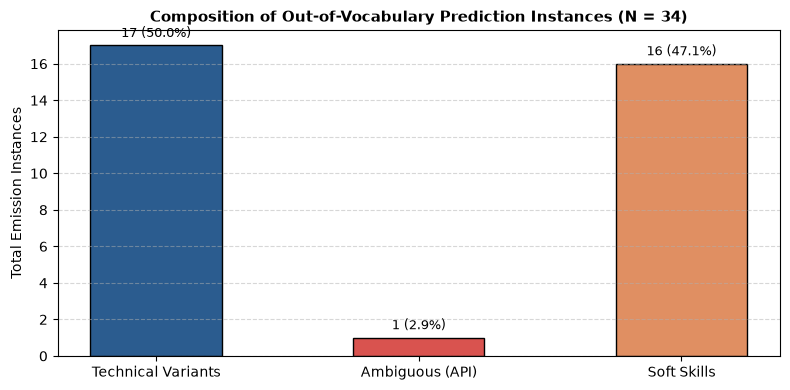

In [11]:
oov_categories = {
    "Technical Variants (Approved Synonyms)": ["Excel", "Node", "Financial Modeling", "JS", "Postgres", "ML", "Social Media"],
    "Ambiguous Technical Terms (Unmapped)": ["API"],
    "Out-of-Vocabulary Soft Skills": ["Leadership", "Teamwork", "Problem Solving", "Communication", "Time Management"],
}

oov_summary_records = []
for category, tag_list in oov_categories.items():
    instances = sum(tag_frequency_series.get(tag, 0) for tag in tag_list)
    oov_summary_records.append(
        {
            "OOV Category": category,
            "Distinct Tags": len(tag_list),
            "Tag Names": ", ".join(tag_list),
            "Total Emission Instances": instances,
            "Percentage of All OOV (%)": round((instances / instance_oov_count) * 100, 2),
            "Percentage of All Predictions (%)": round((instances / len(all_prediction_tokens)) * 100, 2),
        }
    )

eda_oov_analysis_df = pd.DataFrame(oov_summary_records)
eda_oov_analysis_df.to_csv(output_dir / "eda_oov_analysis.csv", index=False)
display(eda_oov_analysis_df)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    ["Technical Variants", "Ambiguous (API)", "Soft Skills"],
    [17, 1, 16],
    color=["#2b5c8f", "#d9534f", "#e08f62"],
    edgecolor="black",
    width=0.5,
)
ax.set_title("Composition of Out-of-Vocabulary Prediction Instances (N = 34)", fontsize=11, fontweight="bold")
ax.set_ylabel("Total Emission Instances", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, yval + 0.3, f"{yval} ({yval/34*100:.1f}%)", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(figures_dir / "oov_breakdown.png", dpi=300)
plt.show()


### 12 : Complete Prediction Frequency Registry


In [12]:
prediction_frequency_records = []
for rank, (tag, count) in enumerate(tag_frequency_series.items(), start=1):
    prediction_frequency_records.append(
        {
            "Rank": rank,
            "Predicted Tag": tag,
            "Emission Count": count,
            "Prevalence (% of JDs)": round((count / len(job_data)) * 100, 2),
            "Canonical Status": "Canonical" if tag in canonical_skills else "Out-of-Vocabulary",
        }
    )

eda_prediction_frequency_df = pd.DataFrame(prediction_frequency_records)
eda_prediction_frequency_df.to_csv(output_dir / "eda_prediction_frequency.csv", index=False)
display(eda_prediction_frequency_df.head(10))


,Rank,Predicted Tag,Emission Count,Prevalence (% of JDs),Canonical Status
0,1,Python,10,20.0,Canonical
1,2,Microsoft Excel,8,16.0,Canonical
2,3,Leadership,7,14.0,Out-of-Vocabulary
3,4,Statistics,6,12.0,Canonical
4,5,SQL,6,12.0,Canonical
5,6,Git,6,12.0,Canonical
6,7,Recruiting,5,10.0,Canonical
7,8,Email Marketing,5,10.0,Canonical
8,9,Excel,5,10.0,Out-of-Vocabulary
9,10,PyTorch,5,10.0,Canonical


### 13 : Job Title and Company Composition


In [13]:
title_counts = job_data["title"].value_counts()
company_counts = job_data["company"].value_counts()

composition_df = pd.DataFrame(
    {
        "Job Title": title_counts.index,
        "JD Count (Title)": title_counts.values,
        "Company": company_counts.index,
        "JD Count (Company)": company_counts.values,
    }
)
display(composition_df)


,Job Title,JD Count (Title),Company,JD Count (Company)
0,Data Analyst Intern,5,Pebble Health,9
1,Frontend Developer Intern,5,Kite Learning,6
2,Backend Developer Intern,5,Tarang Media,6
3,Content Writer Intern,5,Orbit Logistics,5
4,Marketing Intern,5,Saffron Foods,5
5,UI/UX Design Intern,5,Vayu Mobility,5
6,Finance Intern,5,Kosha Fintech,5
7,Machine Learning Intern,5,Lumen Cloud Systems,4
8,Customer Support Intern,5,Brightlane Retail,3
9,HR Intern,5,Nimbus AI Labs,2


### 14 : Textual Structure and Qualification Cues


In [14]:
cue_tests = {
    "Required: 'We need someone who knows'": lambda s: "We need someone who knows" in s,
    "Required: 'You will use ... every day'": lambda s: "every day" in s and "You will use" in s,
    "Required: 'You must be comfortable with'": lambda s: "You must be comfortable with" in s,
    "Required: 'Required:'": lambda s: "Required:" in s,
    "Preferred: 'Bonus if you have used'": lambda s: "Bonus if you have used" in s,
    "Preferred: 'is a plus, not a must'": lambda s: "is a plus, not a must" in s,
    "Preferred: 'Nice to have:'": lambda s: "Nice to have:" in s,
    "Boilerplate: 'Good communication matters in this team'": lambda s: "Good communication matters in this team" in s,
    "Boilerplate: 'Stipend:'": lambda s: "Stipend:" in s,
}

cue_results = []
for cue_name, test_fn in cue_tests.items():
    match_count = job_data["description"].apply(test_fn).sum()
    cue_results.append(
        {
            "Syntactic Cue / Phrase": cue_name,
            "Occurrence Count": int(match_count),
            "Corpus Frequency (%)": round((match_count / len(job_data)) * 100, 2),
        }
    )

cue_df = pd.DataFrame(cue_results)
display(cue_df)


,Syntactic Cue / Phrase,Occurrence Count,Corpus Frequency (%)
0,Required: 'We need someone who knows',14,28.0
1,Required: 'You will use ... every day',19,38.0
2,Required: 'You must be comfortable with',7,14.0
3,Required: 'Required:',10,20.0
4,Preferred: 'Bonus if you have used',20,40.0
5,"Preferred: 'is a plus, not a must'",15,30.0
6,Preferred: 'Nice to have:',15,30.0
7,Boilerplate: 'Good communication matters in th...,50,100.0
8,Boilerplate: 'Stipend:',50,100.0


### 15 : Sample Qualification Statements from Source Text


In [15]:
sample_cues_df = pd.DataFrame(
    [
        {"Category": "Mandatory Requirement", "Example Cue Phrase": "We need someone who knows Python, Statistics and Microsoft Excel", "Observed In": "JD001"},
        {"Category": "Mandatory Requirement", "Example Cue Phrase": "You will use React, TypeScript, CSS and JavaScript every day", "Observed In": "JD002"},
        {"Category": "Mandatory Requirement", "Example Cue Phrase": "You must be comfortable with Docker, REST APIs, PostgreSQL, Node.js and Git", "Observed In": "JD003"},
        {"Category": "Mandatory Requirement", "Example Cue Phrase": "Required: Tally, Accounting and Financial Modelling", "Observed In": "JD017"},
        {"Category": "Preferred Qualification", "Example Cue Phrase": "Data Cleaning is a plus, not a must", "Observed In": "JD001"},
        {"Category": "Preferred Qualification", "Example Cue Phrase": "Nice to have: HTML", "Observed In": "JD002"},
        {"Category": "Preferred Qualification", "Example Cue Phrase": "Bonus if you have used Python", "Observed In": "JD003"},
    ]
)
display(sample_cues_df)


,Category,Example Cue Phrase,Observed In
0,Mandatory Requirement,"We need someone who knows Python, Statistics a...",JD001
1,Mandatory Requirement,"You will use React, TypeScript, CSS and JavaSc...",JD002
2,Mandatory Requirement,"You must be comfortable with Docker, REST APIs...",JD003
3,Mandatory Requirement,"Required: Tally, Accounting and Financial Mode...",JD017
4,Preferred Qualification,"Data Cleaning is a plus, not a must",JD001
5,Preferred Qualification,Nice to have: HTML,JD002
6,Preferred Qualification,Bonus if you have used Python,JD003


### 16 : Export Per-JD Statistics


In [16]:
eda_jd_statistics_df = job_data[
    ["jd_id", "title", "company", "char_length", "word_count", "tag_count"]
].copy()
eda_jd_statistics_df.to_csv(output_dir / "eda_jd_statistics.csv", index=False)
display(eda_jd_statistics_df.head(5))


,jd_id,title,company,char_length,word_count,tag_count
0,JD001,Data Analyst Intern,Kite Learning,291,50,4
1,JD002,Frontend Developer Intern,Orbit Logistics,283,48,3
2,JD003,Backend Developer Intern,Vayu Mobility,296,51,5
3,JD004,Content Writer Intern,Orbit Logistics,284,48,5
4,JD005,Marketing Intern,Nimbus AI Labs,307,51,6
